# Leave one study out
Estimate the pooled range effect with study fixed effects, then omit each study in turn. Student additional analysis using the original five-item satisfaction measure and conventional OLS standard errors.

In [1]:
# Import packages and locate project files.
from pathlib import Path
import os
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/raw/Study 2.xlsx').exists())
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache/matplotlib')
import matplotlib.pyplot as plt
OUT = ROOT / 'additional_robustness_checks'
for folder in ['tables', 'figures']:
    (OUT / folder).mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'pdf.fonttype':42,'savefig.bbox':'tight'})
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 4)


In [2]:
# Pool the original comparable point/range conditions and five-item composite.
ITEMS = ['sb_like','sb_info','sb_useful','sb_accurate','sb_trust']
CONDITIONS = {1:(1,3),2:(1,2),3:(1,2),5:(1,2),6:(2,4),7:(1,3)}
EXPECTED = {1:698,2:599,3:479,5:468,6:801,7:998}
frames, audits = [], []
for study,(point,ranged) in CONDITIONS.items():
    q = pd.read_excel(ROOT / f'data/raw/Study {study}.xlsx')
    raw_n = len(q)
    q = q.loc[(q.ExcludeDuplicateIP != 1) & (q.ExcludeDuplicateID != 1)].copy()
    assert len(q) == EXPECTED[study]
    after_exclusions = len(q)
    q = q.loc[q.Condition.isin([point,ranged])].copy()
    q['study'] = str(study)
    q['range_estimate'] = (q.Condition == ranged).astype(int)
    q['satisfaction'] = q[ITEMS].mean(axis=1,skipna=True)
    audits.append({'study':study,'raw_n':raw_n,'after_original_exclusions':after_exclusions,
                   'comparable_n':len(q),'point_n':(q.range_estimate==0).sum(),
                   'range_n':(q.range_estimate==1).sum(),
                   'missing_composite_n':q.satisfaction.isna().sum(),
                   'partially_missing_items_n':q[ITEMS].isna().any(axis=1).sum()})
    frames.append(q[['study','range_estimate','satisfaction']])
pooled = pd.concat(frames,ignore_index=True)
assert len(pooled) == 2720
assert pooled.satisfaction.notna().all()
audit = pd.DataFrame(audits)
audit.to_csv(OUT / 'tables/loso_sample_audit.csv',index=False)
display(audit)


,study,raw_n,after_original_exclusions,comparable_n,point_n,range_n,missing_composite_n,partially_missing_items_n
0,1,700,698,465,232,233,0,0
1,2,600,599,402,196,206,0,0
2,3,503,479,479,233,246,0,0
3,5,498,468,468,233,235,0,0
4,6,803,801,404,201,203,0,0
5,7,998,998,502,253,249,0,0


In [3]:
# Fit the same study-fixed-effects model in the full sample and after each omission.
rows = []
for omitted in [None]+list(CONDITIONS):
    q = pooled if omitted is None else pooled.loc[pooled.study != str(omitted)]
    fit = smf.ols('satisfaction ~ C(study) + range_estimate',data=q).fit()
    ci = fit.conf_int().loc['range_estimate']
    rows.append({'sample':'Full sample' if omitted is None else f'Exclude Study {omitted}',
                 'omitted_study':omitted,'n':int(fit.nobs),'studies':q.study.nunique(),
                 'b':fit.params['range_estimate'],'se_ols':fit.bse['range_estimate'],
                 'ci_low':ci.iloc[0],'ci_high':ci.iloc[1],'p':fit.pvalues['range_estimate'],
                 'df_resid':fit.df_resid})
results = pd.DataFrame(rows)
results['change_from_full'] = results.b-results.loc[0,'b']
results.to_csv(OUT / 'tables/loso_estimates.csv',index=False)
# Verify OLS independently by subtracting each study's mean from treatment and outcome.
for row in results.itertuples():
    q = pooled if pd.isna(row.omitted_study) else pooled.loc[pooled.study != str(int(row.omitted_study))]
    centered = q[['range_estimate','satisfaction']]-q.groupby('study')[['range_estimate','satisfaction']].transform('mean')
    b_check = (centered.range_estimate*centered.satisfaction).sum()/centered.range_estimate.pow(2).sum()
    assert np.isclose(row.b,b_check,atol=1e-12)
display(results)


,sample,omitted_study,n,studies,b,se_ols,ci_low,ci_high,p,df_resid,change_from_full
0,Full sample,NaN,2720,6,0.7210,0.0471,0.6287,0.8133,6.9124e-51,2713.0,0.0000
1,Exclude Study 1,1.0,2255,5,0.7538,0.0520,0.6517,0.8558,1.5018e-45,2249.0,0.0328
2,Exclude Study 2,2.0,2318,5,0.7275,0.0507,0.6282,0.8269,7.6912e-45,2312.0,0.0065
3,Exclude Study 3,3.0,2241,5,0.7439,0.0521,0.6416,0.8461,3.0221e-44,2235.0,0.0229
4,Exclude Study 5,5.0,2252,5,0.7000,0.0521,0.5978,0.8023,1.3516e-39,2246.0,-0.0210
5,Exclude Study 6,6.0,2316,5,0.6954,0.0503,0.5968,0.7940,8.0704e-42,2310.0,-0.0256
6,Exclude Study 7,7.0,2218,5,0.7058,0.0521,0.6037,0.8079,2.7981e-40,2212.0,-0.0152


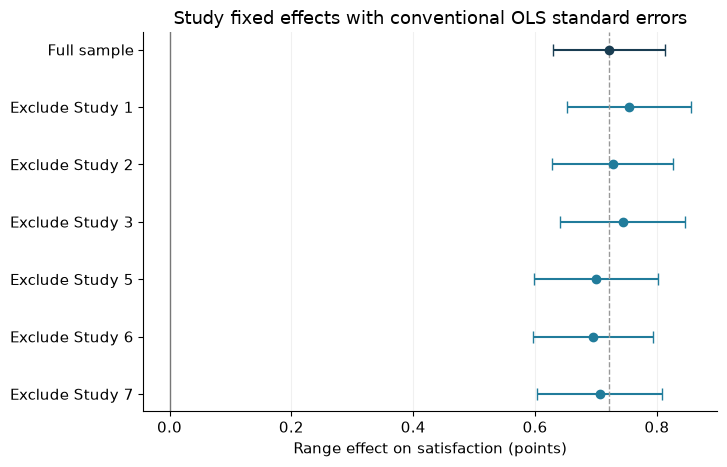

In [4]:
# Plot the full estimate and the six leave-one-study-out estimates.
fig, ax = plt.subplots(figsize=(7.4,4.8))
y = np.arange(len(results))
for i, row in results.iterrows():
    color = '#193d52' if i == 0 else '#217c9b'
    ax.errorbar(row.b,y[i],xerr=[[row.b-row.ci_low],[row.ci_high-row.b]],
                fmt='o',color=color,capsize=4,markersize=6)
ax.axvline(0,color='#777777',linewidth=1)
ax.axvline(results.loc[0,'b'],color='#999999',linestyle='--',linewidth=1)
ax.set(yticks=y,yticklabels=results['sample'],xlabel='Range effect on satisfaction (points)',
       title='Study fixed effects with conventional OLS standard errors')
ax.invert_yaxis();ax.grid(axis='x',alpha=.18)
fig.tight_layout()
for suffix in ['png','pdf']:
    fig.savefig(OUT / f'figures/leave_one_study_out.{suffix}',dpi=300)
plt.show()
